## Pitch Velocity biomechanics analysis
Using Openbiomechanics data from Driveline Baseball to identify what separates pitchers who throw faster.

Begin by opening the poi pitching metrics data using pandas.

In [3]:
import pandas as pd
pitching = pd.read_csv("baseball_pitching/data/poi/poi_metrics.csv")

Print the first 5 rows of the data to get a general sense of the data layout.

In [9]:
pitching.head()


,session_pitch,session,p_throws,pitch_type,pitch_speed_mph,max_shoulder_internal_rotational_velo,max_elbow_extension_velo,max_torso_rotational_velo,max_rotation_hip_shoulder_separation,max_elbow_flexion,...,rear_grf_z_max,rear_grf_mag_max,rear_grf_angle_at_max,lead_grf_x_max,lead_grf_y_max,lead_grf_z_max,lead_grf_mag_max,lead_grf_angle_at_max,peak_rfd_rear,peak_rfd_lead
0,1031_2,1031,R,FF,90.4,4533.2480,2445.8177,958.0878,32.3152,109.9971,...,1497.9859,1736.0368,55.7071,1278.4966,270.7849,2484.8747,2782.9580,63.3501,11.6564,170.4620
1,1031_3,1031,R,FF,90.4,4571.1735,2389.5438,969.5766,32.5547,109.1065,...,1502.8258,1728.0176,60.2863,1436.1255,252.1999,2690.7521,3038.8913,62.3087,9.5715,183.6636
2,1097_1,1097,R,FF,77.6,4165.3055,2426.3029,1090.2269,33.1477,123.4752,...,1094.7686,1283.0751,58.3164,957.3923,245.4411,1767.4604,2010.5341,61.5594,4.4432,52.9333
3,1097_2,1097,R,FF,77.0,3832.1715,2424.0493,1105.2275,27.9286,124.6578,...,1187.5810,1354.7150,58.7397,860.3796,280.5177,1715.1864,1864.0488,66.6789,6.4897,54.3727
4,1097_3,1097,R,FF,76.1,3970.7971,2497.6253,1110.4850,28.9909,124.8308,...,1214.0065,1425.2124,58.0297,1066.6047,337.4227,2120.4510,2283.1749,65.9014,7.2019,106.2719


Print number of rows/columns.

In [6]:
pitching.shape


(411, 81)

Print all possible categories.

In [10]:
pitching.columns.tolist()

['session_pitch',
 'session',
 'p_throws',
 'pitch_type',
 'pitch_speed_mph',
 'max_shoulder_internal_rotational_velo',
 'max_elbow_extension_velo',
 'max_torso_rotational_velo',
 'max_rotation_hip_shoulder_separation',
 'max_elbow_flexion',
 'max_shoulder_external_rotation',
 'elbow_flexion_fp',
 'elbow_pronation_fp',
 'rotation_hip_shoulder_separation_fp',
 'shoulder_horizontal_abduction_fp',
 'shoulder_abduction_fp',
 'shoulder_external_rotation_fp',
 'lead_knee_extension_angular_velo_fp',
 'lead_knee_extension_angular_velo_br',
 'lead_knee_extension_angular_velo_max',
 'torso_anterior_tilt_fp',
 'torso_lateral_tilt_fp',
 'torso_rotation_fp',
 'pelvis_anterior_tilt_fp',
 'pelvis_lateral_tilt_fp',
 'pelvis_rotation_fp',
 'max_cog_velo_x',
 'torso_rotation_min',
 'max_pelvis_rotational_velo',
 'glove_shoulder_horizontal_abduction_fp',
 'glove_shoulder_abduction_fp',
 'glove_shoulder_external_rotation_fp',
 'glove_shoulder_abduction_mer',
 'elbow_flexion_mer',
 'torso_anterior_tilt_mer

Import the dictionary file to identify what each phrase translates to.

In [11]:
dictionary = pd.read_csv("baseball_pitching/data/data_dictionary.csv")
dictionary.head()

,dataset,column,dtype,example,description,documented
0,pitching_poi,session_pitch,str,1031_2,unique pitch ID,True
1,pitching_poi,session,int64,1031,unique session ID,True
2,pitching_poi,p_throws,str,R,pitcher handedness,True
3,pitching_poi,pitch_type,str,FF,pitch type,True
4,pitching_poi,pitch_speed_mph,float64,90.4,pitch speed (miles per hour),True


Format table display to ensure there are no cutoffs.

In [15]:
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", None)

Filter out parts of the dictionary that pertains to the pitching_poi phrases, and list out the descriptions.

In [16]:
dictionary_poi = dictionary[dictionary["dataset"] == "pitching_poi"]
dictionary_poi[["column", "description"]]

,column,description
0,session_pitch,unique pitch ID
1,session,unique session ID
2,p_throws,pitcher handedness
3,pitch_type,pitch type
4,pitch_speed_mph,pitch speed (miles per hour)
5,max_shoulder_internal_rotational_velo,peak shoulder internal rotation velocity (deg/s)
6,max_elbow_extension_velo,peak elbow extension velocity (deg/s)
7,max_torso_rotational_velo,peak torso axial rotation (Z) velocity (deg/s)
8,max_rotation_hip_shoulder_separation,peak separation between thorax and pelvis (deg)
9,max_elbow_flexion,peak elbow flexion angle (deg)


Pick 7 columns of interest. 

Energy flow
pelvis_lumbar_transfer_fp_br
lead_hip_transfer_fp_br	
lead_knee_generation_fp_br

low. body
max_cog_velo_x	(center of grav)
pelvis_lateral_tilt_fp

rotation
max_torso_rotational_velo	
torso_rotation_min	


pitch_speed_mph	(target)

Using .describe, print the count, mean, spread, range of each column.

In [19]:
cols = [
    "pitch_speed_mph",
    "max_torso_rotational_velo",
    "torso_rotation_min",
    "pelvis_lumbar_transfer_fp_br",
    "lead_hip_transfer_fp_br",
    "lead_knee_generation_fp_br",
    "max_cog_velo_x",
    "pelvis_lateral_tilt_fp",
]

focus_df = pitching[cols]
focus_df.describe()

,pitch_speed_mph,max_torso_rotational_velo,torso_rotation_min,pelvis_lumbar_transfer_fp_br,lead_hip_transfer_fp_br,lead_knee_generation_fp_br,max_cog_velo_x,pelvis_lateral_tilt_fp
count,411.000000,411.000000,411.000000,403.000000,403.000000,403.000000,411.000000,411.000000
mean,84.703650,1054.802963,-38.528789,139.145452,48.542247,33.467364,3.055969,-0.092674
std,4.717685,88.359211,9.992994,76.745665,27.709113,19.211350,0.255493,4.592526
min,69.500000,848.383600,-75.700100,14.266100,5.881000,0.098100,2.273600,-12.729500
25%,81.400000,997.259350,-43.634750,91.003000,27.836500,18.632200,2.911000,-3.349550
50%,85.300000,1049.691500,-37.539800,120.303100,42.777600,32.493300,3.075400,-0.117400
75%,87.900000,1110.142600,-31.140450,170.342400,67.809600,44.327300,3.238500,2.477250
max,94.400000,1383.236700,-19.088800,639.757700,152.272900,92.534400,3.583500,16.872300


Check for missing values.

In [20]:
focus_df.isnull().sum()

pitch_speed_mph                 0
max_torso_rotational_velo       0
torso_rotation_min              0
pelvis_lumbar_transfer_fp_br    8
lead_hip_transfer_fp_br         8
lead_knee_generation_fp_br      8
max_cog_velo_x                  0
pelvis_lateral_tilt_fp          0
dtype: int64

Calculate each columns correlation with pitch speed.

In [24]:
focus_df.corr()["pitch_speed_mph"].sort_values(ascending=False)

pitch_speed_mph                 1.000000
max_torso_rotational_velo       0.327816
max_cog_velo_x                  0.201060
lead_hip_transfer_fp_br         0.160650
pelvis_lumbar_transfer_fp_br    0.139930
lead_knee_generation_fp_br      0.116655
torso_rotation_min             -0.031026
pelvis_lateral_tilt_fp         -0.055647
Name: pitch_speed_mph, dtype: float64

Torso rotational velocity had the highest correlation out of the 7 columns.

Create plot between max torso rotational velocity and the pitch speed.

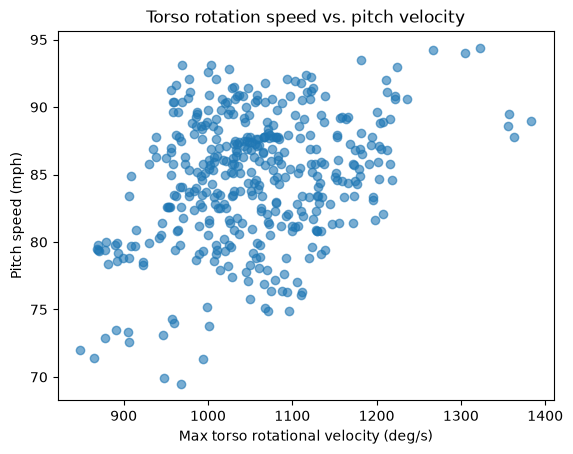

In [25]:
import matplotlib.pyplot as plt

plt.scatter(focus_df["max_torso_rotational_velo"], focus_df["pitch_speed_mph"], alpha=0.6)
plt.xlabel("Max torso rotational velocity (deg/s)")
plt.ylabel("Pitch speed (mph)")
plt.title("Torso rotation speed vs. pitch velocity")
plt.show()

Calculate correlation again by average of each pitcher.

In [26]:
per_session = pitching.groupby("session")[cols].mean()
print(per_session.shape)
per_session.corr()["pitch_speed_mph"].sort_values(ascending=False)

(100, 8)


pitch_speed_mph                 1.000000
max_torso_rotational_velo       0.328013
max_cog_velo_x                  0.225410
lead_hip_transfer_fp_br         0.190704
pelvis_lumbar_transfer_fp_br    0.179225
lead_knee_generation_fp_br      0.164961
torso_rotation_min             -0.018788
pelvis_lateral_tilt_fp         -0.046469
Name: pitch_speed_mph, dtype: float64

Create plot with max torso rotational velocity averaged per pitcher against pitch speed, create line of best fit. 

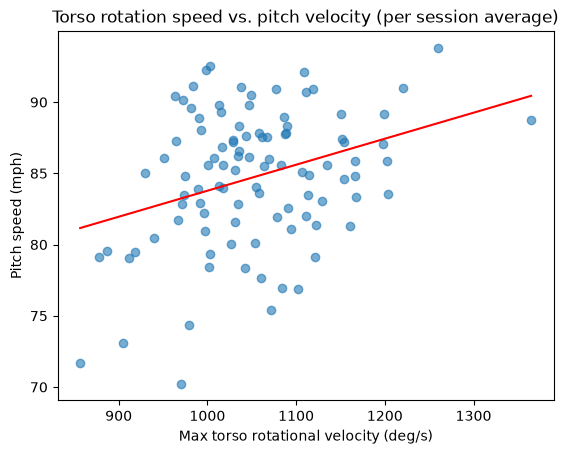

In [28]:
import numpy as np
x = per_session["max_torso_rotational_velo"]
y = per_session["pitch_speed_mph"]
slope, intercept = np.polyfit(x, y, 1)

plt.scatter(x, y, alpha=0.6)
plt.plot(x.sort_values(), slope * x.sort_values() + intercept, color="red")
plt.xlabel("Max torso rotational velocity (deg/s)")
plt.ylabel("Pitch speed (mph)")
plt.title("Torso rotation speed vs. pitch velocity (per session average)")
plt.show()

In [29]:
print(f"About {slope * 100:.1f} mph per 100 deg/s of torso rotation")

About 1.8 mph per 100 deg/s of torso rotation


Second highest correlation is max cog (center of gravity), create graph with line of best fit.

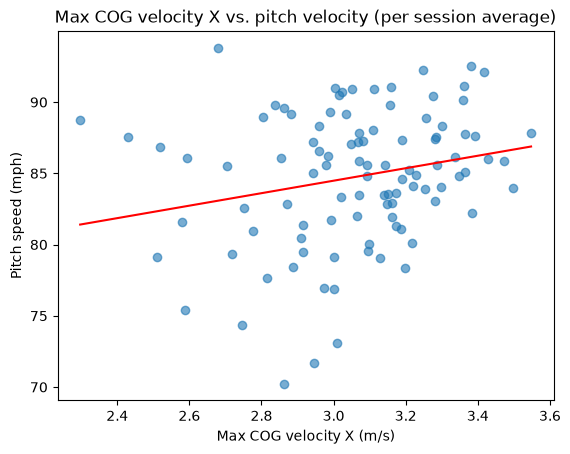

In [32]:
x = per_session["max_cog_velo_x"]
y = per_session["pitch_speed_mph"]
slope, intercept = np.polyfit(x, y, 1)

plt.scatter(x, y, alpha=0.6)
plt.plot(x.sort_values(), slope * x.sort_values() + intercept, color="red")
plt.xlabel("Max COG velocity X (m/s)")
plt.ylabel("Pitch speed (mph)")
plt.title("Max COG velocity X vs. pitch velocity (per session average)")
plt.show()

Find median pitch speed across all sections and split sessions into either higher than median or lower.

In [33]:
median_speed = per_session["pitch_speed_mph"].median()
per_session["group"] = np.where(per_session["pitch_speed_mph"] >= median_speed, "Faster", "Slower")

per_session.groupby("group")[["max_torso_rotational_velo", "max_cog_velo_x"]].mean()

,max_torso_rotational_velo,max_cog_velo_x
group,,
Faster,1071.426072,3.079979
Slower,1034.476769,3.039519


Faster group averaged higher max torso rotational velocity, and slightly higher max cog velocity. 

Create box plots for faster and slower pitchers in regards to torso rotational velocity and cog velocity.

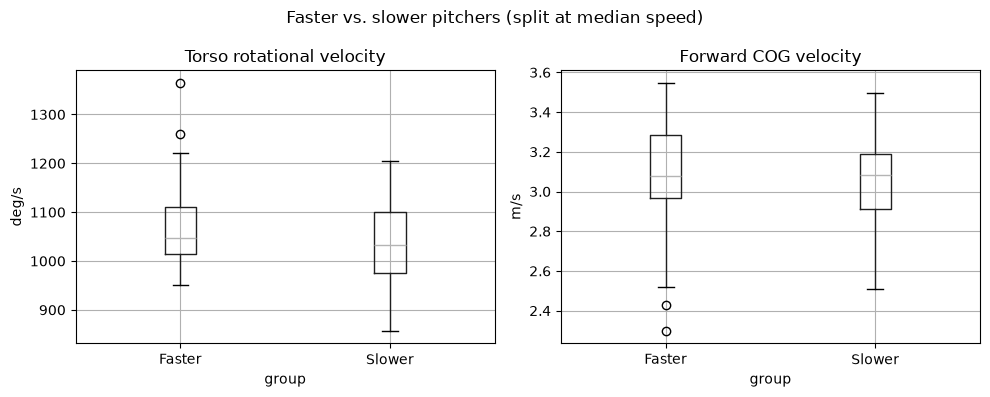

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

per_session.boxplot(column="max_torso_rotational_velo", by="group", ax=axes[0])
axes[0].set_title("Torso rotational velocity")
axes[0].set_ylabel("deg/s")

per_session.boxplot(column="max_cog_velo_x", by="group", ax=axes[1])
axes[1].set_title("Forward COG velocity")
axes[1].set_ylabel("m/s")

plt.suptitle("Faster vs. slower pitchers (split at median speed)")
plt.tight_layout()
plt.show()

## Key findings
- Peak torso rotational velocity had the strongest association with pitch speed (r = 0.33).
- Each additional 100 deg/s of torso rotation was associated with about 1.8 mph higher pitch speed on average.
- Forward center-of-gravity velocity showed a weaker relationship, energy flow showed even weaker associations.
- No single metric explained velocity strongly, a combination of factors might have contributed to a faster pitch.

## Data
411 fastballs from about 100 mostly collegiate pitchers, from the [OpenBiomechanics Project](https://github.com/drivelineresearch/openbiomechanics) by Driveline Baseball. Data not included in this repo.

## Methods
- Selected 7 metrics covering rotation, lower-body momentum, and energy flow
- Computed correlations with pitch speed
- Averaged pitches by session to correct for repeated trials from the same pitcher
- Fit linear trend lines and compared faster vs. slower pitchers (split at median speed)

## Limitations
Results are correlational and don't show cause. The sample is mostly collegiate pitchers throwing fastballs.
